In [ ]:
# yaml processing file loading. 
import yaml
from os.path import  join

from time import time
from stl import mesh
from pc_centrelines.utils import array_to_o3d
from pc_centrelines.LBC_centreline import return_LBC_centreline


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [5]:
with open(f"../notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

In [6]:
lbc_times = []
lbc_sizes = []

In [9]:
## big loop, storing time taken to compute the LBC centrelines. 
for ID in range(1, 13):
    CONDUIT_NAME = conduit_map[ID]
    ## import the mesh data. 
    mesh_fp =  f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
    data = mesh.Mesh.from_file(mesh_fp)
    lbc_centreline_fp = join(f"../temp/{ID}_{CONDUIT_NAME}/lbc/", f"{CONDUIT_NAME}_centreline.txt")

    pcd = data.centroids
    # convert to open3d object-
    pcd = array_to_o3d(pcd)

    with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
        process_p = yaml.safe_load(f)
        f.close()

    # definition of processing metaparameters
    lbc_args = dict(init_attraction = process_p["lbc"]["initAttraction"], 
                    init_contraction = process_p["lbc"]["initContraction"],
                    down_sample = process_p["lbc"]["voxelSize"])

    ct_args = dict(keep = True, keep_centreline = False, centreline_down_sample = process_p["lbc"]["downSample"])
    
    s = time()

    out_LBC = return_LBC_centreline(data,
                            ct_args= ct_args,
                            lbc_args= lbc_args)
    e= time()
    lbc_times.append(e-s)
    lbc_sizes.append(out_LBC["skeleton_cloud_size"])
    print(f"conduit {ID}: {e-s:.6f}s")

read file in 0.0000s


2026-09-23 13:52:43,468 - PCD #points: 2000


contracted file in 0.2969s


Volume ratio: 1.0. Contraction weights: 354.0875757639706. Attraction weights: 4.278736902212761. Progress LBC:  10%|█         | 2/20 [00:00<00:02,  8.16it/s]2026-09-23 13:52:43,914 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 354.0875757639706. Attraction weights: 4.278736902212761. Progress LBC:  15%|█▌        | 3/20 [00:00<00:02,  7.86it/s]


Contraction is Done.
extracted skeleton in 0.4519s
downsampled the centreline cloud in 0.0005s
16
found largest component in 0.0007s
computed minimum spanning tree in 0.7030s
created graph instance of the centreline in  0.0000s
added node coordinates to graph in  0.0000s
this minimum spanning tree has 2 leaves. Need to identify the best path.
conduit 1: 1.454993s
read file in 0.0000s


...

read file in 0.0000s


2026-09-23 13:53:17,012 - PCD #points: 5336


contracted file in 0.6904s


Volume ratio: 1.0. Contraction weights: 701.1236054312379. Attraction weights: 21.925994962334336. Progress LBC:  15%|█▌        | 3/20 [00:00<00:04,  3.63it/s]2026-09-23 13:53:18,322 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 701.1236054312379. Attraction weights: 21.925994962334336. Progress LBC:  15%|█▌        | 3/20 [00:01<00:06,  2.77it/s]

Contraction is Done.
extracted skeleton in 1.3247s
downsampled the centreline cloud in 0.0000s
96
found largest component in 0.0010s
computed minimum spanning tree in 0.0075s
created graph instance of the centreline in  0.0000s
added node coordinates to graph in  0.0000s
this minimum spanning tree has 4 leaves. Need to identify the best path.
conduit 12: 2.024580s


In [10]:
lbc_sizes, lbc_times

([2000, 1503, 2289, 1833, 2513, 4567, 5541, 3824, 5855, 15900, 4589, 5336],
 [1.4549927711486816,
  0.6633965969085693,
  1.1066224575042725,
  1.0375292301177979,
  0.930006742477417,
  1.981532096862793,
  2.293813943862915,
  1.5918309688568115,
  3.2907145023345947,
  9.515174627304077,
  1.291309118270874,
  2.0245795249938965])

In [12]:
import matplotlib.pyplot as plt 

In [14]:
import numpy as np
from os import makedirs
from os.path import exists, isdir
from MST_centreline import return_MST_centrelines
from utils import return_edge_midpoints, find_neighbours_with_knn, adjust_plane

In [101]:
adj_matrix_sizes = []
adj_matrix_times = []


In [102]:
for ID in range(1,13):
    CONDUIT_NAME = conduit_map[ID]
    ## import the mesh data. 
    mesh_fp =  f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
    data = mesh.Mesh.from_file(mesh_fp)
    
    with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
        process_p = yaml.safe_load(f)
        f.close()
        
    s = time()
    triangle_adjacency_matrix = find_neighbours_with_knn(data)
    e = time()
    adj_matrix_sizes.append(len(triangle_adjacency_matrix))
    adj_matrix_times.append(e-s)

100%|██████████| 347858/347858 [00:24<00:00, 14461.79it/s]


knn search complete and neighbouring triangles found in:  

25.421581268310547  s


100%|██████████| 317774/317774 [00:22<00:00, 14245.41it/s]


knn search complete and neighbouring triangles found in:  

23.48290514945984  s


100%|██████████| 415926/415926 [00:29<00:00, 14255.98it/s]


...

knn search complete and neighbouring triangles found in:  

1015.4405539035797  s


100%|██████████| 229082/229082 [01:31<00:00, 2506.82it/s]


knn search complete and neighbouring triangles found in:  

94.17470216751099  s


100%|██████████| 763406/763406 [01:16<00:00, 10011.08it/s]

knn search complete and neighbouring triangles found in:  

85.4326171875  s


In [15]:
mst_sizes=[]
mst_times=[]

In [17]:
for ID in range(1,13):
    CONDUIT_NAME = conduit_map[ID]
    ## import the mesh data. 
    mesh_fp =  f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
    data = mesh.Mesh.from_file(mesh_fp)
    
    with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
        process_p = yaml.safe_load(f)
        f.close()
        
    adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
    if not exists(adj_triangles_fp):
        triangle_adjacency_matrix = find_neighbours_with_knn(data)
        np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
    else: 
        triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)


    ## find the rings (the largest two clusters of points lying on edges.)
    edge_midpoints, labels = return_edge_midpoints(data, triangle_adjacency_matrix)
    ## fit a plane into the direction of the passage. 
    # find the two largest connected components associated with rings. 

    # find out the size of the connected components
    cc_sizes = [np.sum(labels == c) for c in np.unique(labels)  if c >=0]
    # order the indices by decreasing size.
    cc_argsort = np.argsort(cc_sizes)[::-1]

    # index the rings by their dbscan label and return only the edge midpoint coordinates.
    ring1 = edge_midpoints[labels==cc_argsort[0]]
    ring2 = edge_midpoints[labels==cc_argsort[1]]

    P1, nP1 = adjust_plane(ring1)
    P2, nP2 = adjust_plane(ring2)

    voxelsize = process_p["mst"]["voxelSize"]

    P1_neighbours = np.logical_and(np.abs((P1 - data.centroids) @ nP1)  < 2 *voxelsize,
                               np.linalg.norm((P1 - data.centroids), axis=1)  < 10 *voxelsize)
    P2_neighbours = np.logical_and(np.abs((P2 - data.centroids) @ nP2)  < 2 *voxelsize, 
                               np.linalg.norm((P2 - data.centroids), axis=1)  < 10 *voxelsize)
    
    sign_P1 = np.sign(nP1 @ (np.mean(data.centroids[P1_neighbours], axis =0) - P1))
    sign_P2 = np.sign(nP2 @ (np.mean(data.centroids[P2_neighbours], axis =0) - P2))

    P1_in = np.mean(ring1, axis =0)+ nP1*sign_P1*voxelsize*0.01
    P2_in = np.mean(ring2, axis =0)+ nP2*sign_P2*voxelsize*0.01

    voxset_fp = mesh_fp[:-4] + "_voxset.vxl"
    
    s = time()
    out_MST = return_MST_centrelines(mesh_fp, voxset_path=voxset_fp, 
                             delta = int(voxelsize*1000), 
                             P1=P1_in, 
                             P2=P2_in, 
                             verbose = False)
    e= time()
    
    mst_times.append(e-s)
    mst_sizes.append(out_MST["original_grid_points"])
    print(f"conduit {ID}: {e-s:.6f}s")

Read 'c:\Users\tangr\GitHub\pc-centrelines\data\1_straight_cyl\straight_cyl_voxset.vxl': 174,644 vertices and 3,722 grid points,
Added edges in 1.0 sec.
Computed maximum spanning tree for clearance in 0.0 sec.
Computed path in maximum spanning tree in 0.0 sec.
Polyline has 51 vertices
Simplified polyline has 2 vertices


Added edges in 0.0 sec.
Computed shortest path in 0.0 sec.
simplified polyline has fewer than 2 vertices. Impossible to simplify further.
conduit 1: 3.481029s


Read 'c:\Users\tangr\GitHub\pc-centrelines\data\2_straight_elp\straight_elp_voxset.vxl': 159,426 vertices and 2,015 grid points,
Added edges in 0.4 sec.
Computed maximum spanning tree for clearance in 0.0 sec.
Computed path in maximum spanning tree in 0.0 sec.


Added edges in 0.0 sec.
Computed shortest path in 0.0 sec.


Polyline has 51 vertices
Simplified polyline has 2 vertices


...

Polyline has 126 vertices
Simplified polyline has 30 vertices


conduit 11: 1.391974s


Read 'c:\Users\tangr\GitHub\pc-centrelines\data\12_lauiloch\lauiloch_voxset.vxl': 381,892 vertices and 3,776 grid points,
Added edges in 0.3 sec.
Computed maximum spanning tree for clearance in 0.0 sec.
Computed path in maximum spanning tree in 0.0 sec.


Added edges in 0.1 sec.
Computed shortest path in 0.0 sec.
conduit 12: 2.513902s


Polyline has 146 vertices
Simplified polyline has 42 vertices


In [18]:
mst_sizes, mst_times

([3722, 2015, 3989, 2998, 3181, 6300, 9487, 3752, 7507, 31416, 3332, 3776],
 [3.4810290336608887,
  1.443244218826294,
  2.3252289295196533,
  2.644693613052368,
  1.9168434143066406,
  2.3704042434692383,
  2.93506121635437,
  2.2397892475128174,
  6.6374006271362305,
  16.065199375152588,
  1.3919742107391357,
  2.513902187347412])

In [29]:
iter_sizes = []
iter_times = []

In [30]:
from iterative_section_minimiser import iterative_pathfinder, mesh_intersect

In [31]:
for ID in range(1,13):
    CONDUIT_NAME = conduit_map[ID]
    ## import the mesh data. 
    mesh_fp =  f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
    data = mesh.Mesh.from_file(mesh_fp)
    
    with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
        process_p = yaml.safe_load(f)
        f.close()

    iterative_ct_fp = join("../temp/", f"{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_centreline.txt") 
    sections_fp = f"../temp/{ID}_{CONDUIT_NAME}/iterative/sections2d"
    sections3d_fp = f"../temp/{ID}_{CONDUIT_NAME}/iterative/sections3d"
    iterative_vectors_fp = join("../temp/", f"{ID}_{CONDUIT_NAME}/iterative/{CONDUIT_NAME}_vectors.txt") 

    adj_triangles_fp = mesh_fp[:-4] + "_adjacent_triangles.txt"
    if not exists(adj_triangles_fp):
        triangle_adjacency_matrix = find_neighbours_with_knn(data)
        np.savetxt(adj_triangles_fp, triangle_adjacency_matrix)
    else: 
        triangle_adjacency_matrix = np.loadtxt(adj_triangles_fp)


    ## find the rings (the largest two clusters of points lying on edges.)
    edge_midpoints, labels = return_edge_midpoints(data, triangle_adjacency_matrix)
    ## fit a plane into the direction of the passage. 
    # find the two largest connected components associated with rings. 

    # find out the size of the connected components
    cc_sizes = [np.sum(labels == c) for c in np.unique(labels)  if c >=0]
    # order the indices by decreasing size.
    cc_argsort = np.argsort(cc_sizes)[::-1]

    # index the rings by their dbscan label and return only the edge midpoint coordinates.
    ring1 = edge_midpoints[labels==cc_argsort[0]]
    ring2 = edge_midpoints[labels==cc_argsort[1]]

    P1, nP1 = adjust_plane(ring1)
    P2, nP2 = adjust_plane(ring2)

    ds = process_p["iterStepSize"]

    P1_neighbours = np.logical_and(np.abs((P1 - data.centroids) @ nP1)  < 2 *voxelsize,
                               np.linalg.norm((P1 - data.centroids), axis=1)  < 10 *voxelsize)
    P2_neighbours = np.logical_and(np.abs((P2 - data.centroids) @ nP2)  < 2 *voxelsize, 
                               np.linalg.norm((P2 - data.centroids), axis=1)  < 10 *voxelsize)
    
    sign_P1 = np.sign(nP1 @ (np.mean(data.centroids[P1_neighbours], axis =0) - P1))
    sign_P2 = np.sign(nP2 @ (np.mean(data.centroids[P2_neighbours], axis =0) - P2))

    for step in np.linspace(0.1, 2, 10):
        P1_in = np.mean(ring1, axis =0)+ nP1*sign_P1*ds*step
        P2_in = np.mean(ring2, axis =0)+ nP2*sign_P2*ds*step


        s= time()
        out = mesh_intersect(theMesh=data, 
                            P=P1_in,
                            nP=nP1*sign_P1.flatten())
        e = time()

        iter_times.append(e-s)
        #iter_times.append(len(out_iterative["centreline"]))
        iter_sizes.append(len(data.centroids))


        s= time()
        out = mesh_intersect(theMesh=data, 
                            P=P2_in,
                            nP=nP2*sign_P2.flatten())
        e = time()

        iter_times.append(e-s)
        #iter_times.append(len(out_iterative["centreline"]))
        iter_sizes.append(len(data.centroids))




In [36]:
iter_sizes = np.array(iter_sizes[::20].copy())

In [42]:

iter_times_mean = np.array([np.mean(iter_times[20*k:20*k+20]) for k in range(12)])



In [47]:
def return_powerlaw(u, v):
# power laws if they exist. 

    x = np.log(u)
    y = np.log(v)

    G = np.ones((12, 2))
    G[:, 0] = x
    p = np.linalg.inv(G.T @ G) @ G.T @ y
    xi = np.linspace(np.min(x), np.max(x),20)
    yi = p[0] *xi + p[1]
    ui = np.exp(xi)
    vi = np.exp(yi)

    return ui, vi, p


In [103]:
adj_matrix_sizes

[347858,
 317774,
 415926,
 528965,
 410243,
 390658,
 255785,
 571505,
 1794452,
 2472532,
 229082,
 763406]

In [104]:
adj_matrix_times

[25.421581268310547,
 23.48290514945984,
 30.831825971603394,
 39.183085918426514,
 30.278743743896484,
 28.896466970443726,
 18.751237154006958,
 41.70045518875122,
 464.2634925842285,
 1015.5131597518921,
 94.19128799438477,
 85.43925547599792]

[ 0.98140818 -7.53374711] [ 0.81980979 -5.90284535] [  0.72758196 -10.77473074] [  1.49848785 -15.65607216]


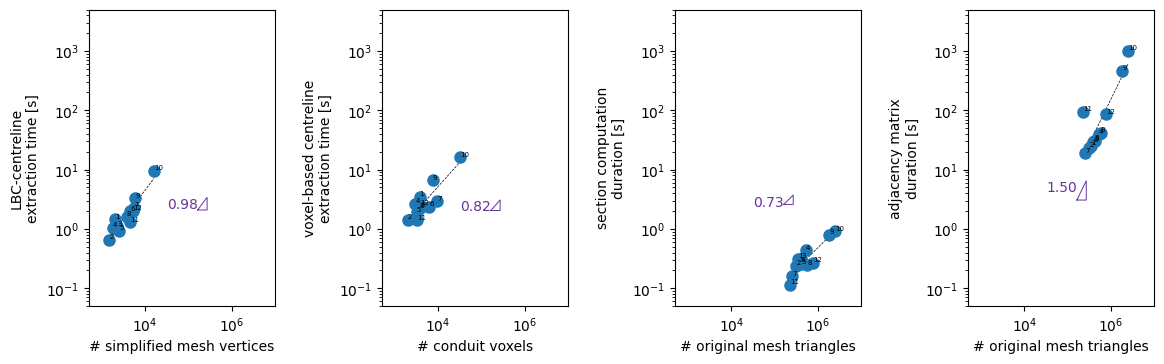

In [111]:
fig, axes = plt.subplots(1,4, figsize = (12, 4))

axes[0].loglog(lbc_sizes, lbc_times, "o", markersize = 8)
ui, vi, p1 = return_powerlaw(lbc_sizes, lbc_times)
axes[0].plot(ui, vi, color = "k", ls = "--", zorder = -10, lw = 0.5)

axes[1].loglog(mst_sizes, mst_times, "o", markersize = 8)
ui, vi, p2 = return_powerlaw(mst_sizes, mst_times)
axes[1].plot(ui, vi, color = "k", ls = "--", zorder = -10, lw = 0.5)

axes[2].loglog(iter_sizes, iter_times_mean, "o", markersize = 8)
ui, vi, p3 = return_powerlaw(iter_sizes, iter_times_mean)
axes[2].plot(ui, vi, color = "k", ls = "--", zorder = -10, lw = 0.5)

axes[3].loglog(adj_matrix_sizes, adj_matrix_times, "o", markersize = 8)
ui, vi, p4 = return_powerlaw(adj_matrix_sizes, adj_matrix_times)
axes[3].plot(ui, vi, color = "k", ls = "--", zorder = -10, lw = 0.5)


for i in range(1,13):
    axes[0].text(lbc_sizes[i-1], lbc_times[i-1], i, va = "bottom", fontsize = 5)
    axes[1].text(mst_sizes[i-1], mst_times[i-1], i, va = "bottom", fontsize = 5)
    axes[2].text(iter_sizes[i-1], iter_times_mean[i-1], i, va = "bottom", fontsize = 5)
    axes[3].text(adj_matrix_sizes[i-1], adj_matrix_times[i-1], i, va = "bottom", fontsize = 5)

axes[0].set_xlabel("# simplified mesh vertices")
axes[0].set_ylabel("LBC-centreline\nextraction time [s]")

axes[1].set_xlabel("# conduit voxels")
axes[1].set_ylabel("voxel-based centreline\nextraction time [s]")

axes[2].set_xlabel("# original mesh triangles")
axes[2].set_ylabel("section computation\nduration [s]")

axes[3].set_xlabel("# original mesh triangles")
axes[3].set_ylabel("adjacency matrix\nduration [s]")


print(p1, p2, p3, p4)
scales = [3e-2, 4e-2, 2e1, 3e-1]


for ax, p, scale in zip(axes, (p1, p2, p3, p4), scales):
    ax.set_xlim(5e2, 1e7)
    ax.set_ylim(5e-2, 5e3)
    triangle_x = [np.exp(12), np.exp(12.5), np.exp(12.5), np.exp(12)]
    triangle_y = [scale*np.exp(p[1])*np.exp(p[0]*12), scale*np.exp(p[1])*np.exp(p[0]*12.5), scale*np.exp(p[1])*np.exp(p[0]*12),scale*np.exp(p[1])*np.exp(p[0]*12)]
    
    ax.plot(triangle_x, triangle_y, color = "rebeccapurple", lw = 0.7)
    ax.text(np.exp(12), scale*np.exp(p[1])*np.exp(p[0]*12.5), f"{p[0]:.2f}", va = "top", ha="right", color = "rebeccapurple")

    fig.tight_layout(pad=2.0) # Adjust padding

plt.savefig("../temp/figures/summary_computation_time_needed.pdf")
plt.savefig("../temp/figures/summary_computation_time_needed.png", dpi = 300)
